# Interest-Rate Risk in the Banking Book from U.S. Call Reports: Synthetic Banks Built from Repricing Buckets, Behavioural Deposits, EVE and NII under the Basel Shocks, and Whether the 2021 Measures Foresaw 2022–2023

At the end of 2021 U.S. banks held record deposits, much of them invested in long fixed-rate securities and mortgages bought at near-zero rates. Over the next two years the Federal Reserve raised its policy rate by more than five points. Securities lost hundreds of billions of dollars in value, depositors moved money to higher-yielding alternatives, and in 2023 three large banks failed. Supervisors measure this risk with two standard tools: the change in the economic value of equity (EVE) under six prescribed rate shocks, and the change in net interest income (NII) over the next year. This notebook rebuilds both measures for every U.S. bank from its public call report, and then asks whether they, or a machine-learning model, saw the damage coming.

**What it does.**

1. It downloads the quarterly call-report data of every FDIC-insured bank from 2015 to 2026: repricing and maturity buckets of loans, securities, time deposits and borrowings; deposit mix; uninsured deposits; interest income and expense; and the fair value of securities.
2. It builds a **synthetic bank** for each size group (community, regional, large) and the cash flows of every individual bank from those buckets. Non-maturity deposits are treated behaviourally, with the Basel caps on stable deposits and their maturity.
3. It computes ΔEVE under the six Basel shocks and ΔNII under ±200 bp parallel shocks for every bank at the end of 2021, and runs the Basel outlier test (worst ΔEVE above 15% of Tier 1 capital).
4. It checks the 2021 measures against what happened:
   - the securities losses of 2022, given the actual move of the Treasury curve;
   - the deposit-rate pass-through (deposit beta) of 2022–2023, predicted from the 2015–2019 cycle with a cross-sectional model and with gradient boosting;
   - the change in net interest margin, with models trained on the 2015–2019 hiking cycle and tested on 2021–2023;
   - the banks that failed.

**Data.** FDIC BankFind Suite financial data (call reports) and the list of failed banks; Treasury constant-maturity yields and the effective federal funds rate (FRED).

**Methods.** Repricing-gap cash-flow construction, BCBS 368 standardised interest-rate shocks with a maturity-dependent floor, behavioural slotting of non-maturity deposits, deposit betas, ΔEVE and ΔNII, a duration check against realised securities losses, out-of-time ridge regression and LightGBM, and SHAP attribution.

**Key output.** The distribution of ΔEVE and ΔNII across U.S. banks at the end of 2021; the synthetic banks by size; how well bucket-based durations explain the 2022 securities losses; how predictable the 2022–2023 deposit betas and margin changes were; and where the failed banks sat.

## 1. Interest-rate risk in the banking book

**Two lenses.** *Economic value of equity* (EVE) is the present value of assets minus the present value of liabilities. When rates rise, long fixed-rate assets lose more value than short liabilities, so EVE falls. *Net interest income* (NII) is what the bank earns over the next year; when rates rise, it rises if assets reprice faster than liabilities.

**The standardised framework (BCBS 368, 2016).** Banks report ΔEVE under six shocks: parallel up and down, short-rate up and down, steepener and flattener. For the U.S. dollar the shock sizes are 200 bp (parallel), 300 bp (short) and 150 bp (long). A bank whose worst ΔEVE exceeds 15% of Tier 1 capital is an outlier and draws supervisory attention.

**Non-maturity deposits.** Checking and savings accounts have no maturity but in practice stay for years and pay rates that lag the market. Their treatment drives the answer:
- the *stable (core)* share is capped by the standard: 90% of retail transactional deposits, 70% of retail non-transactional deposits and 50% of wholesale deposits;
- the core share is spread over maturities whose average cannot exceed 5, 4.5 and 4 years respectively;
- the *deposit beta* is the share of a policy-rate move passed on to depositors; it decides how quickly funding costs rise in NII.

**What the call report shows.** Schedules RC-B and RC-C report securities and loans by *remaining maturity* (fixed rate) or *next repricing date* (floating rate) in six buckets. Schedule RC-E reports time deposits in four buckets, and RC-M other borrowings in four. That is enough to rebuild an approximate repricing profile for every bank. It is not enough to see amortisation, prepayments or hedges with derivatives, and the analysis measures what that costs.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import shap
from scipy.interpolate import interp1d
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2023
rng = np.random.default_rng(SEED)
FDIC_API = "https://api.fdic.gov/banks"
START_Q, AS_OF = "2015-12-31", "2021-12-31"
TENORS = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}
SHOCK = {"parallel": 0.02, "short": 0.03, "long": 0.015}  # USD, BCBS 368
OUTLIER = 0.15  # of Tier 1
SIZE_GROUPS = [
    (0, 1e6, "community (<$1bn)"),
    (1e6, 1e7, "community ($1–10bn)"),
    (1e7, 1e8, "regional ($10–100bn)"),
    (1e8, np.inf, "large (>$100bn)"),
]

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · run on 2026-11-03


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Call reports for every bank, 2015–2026

The FDIC's BankFind API returns the call-report variables of every insured bank by quarter, in thousands of dollars. About sixty variables are kept: total assets, equity and Tier 1 capital; loans, securities, time deposits and borrowings by bucket; deposits by type and the uninsured share; interest income and expense; and amortised cost and fair value of securities.

In [3]:
BUCKETS = {
    # asset buckets: (fields, midpoints in years)
    "RE 1–4 family loans": (
        ["LNRS3LES", "LNRS3T12", "LNRS1T3", "LNRS3T5", "LNRS5T15", "LNRSOV15"],
        [0.125, 0.625, 2, 4, 10, 20],
    ),
    "other loans": (
        ["LNOT3LES", "LNOT3T12", "LNOT1T3", "LNOT3T5", "LNOT5T15", "LNOTOV15"],
        [0.125, 0.625, 2, 4, 10, 20],
    ),
    "non-mortgage securities": (
        ["SCNM3LES", "SCNM3T12", "SCNM1T3", "SCNM3T5", "SCNM5T15", "SCNMOV15"],
        [0.125, 0.625, 2, 4, 10, 20],
    ),
    "mortgage pass-throughs": (
        ["SCPT3LES", "SCPT3T12", "SCPT1T3", "SCPT3T5", "SCPT5T15", "SCPTOV15"],
        [0.125, 0.625, 2, 4, 10, 20],
    ),
    "other mortgage securities": (["SCO3YLES", "SCOOV3Y"], [1.5, 7]),
}
LIAB_BUCKETS = {
    "time deposits": (
        ["CD3LESS", "CD3T12S", "CD1T3S", "CDOV3S"],
        [0.125, 0.625, 2, 4],
    ),
    "large time deposits": (
        ["CD3LES", "CD3T12", "CD1T3", "CDOV3"],
        [0.125, 0.625, 2, 4],
    ),
    "other borrowings": (
        ["OTBOT1L", "OTBOT1T3", "OTBOT3T5", "OTBOTOV5"],
        [0.5, 2, 4, 7],
    ),
}
OTHER = [
    "CERT",
    "REPDTE",
    "NAME",
    "STNAME",
    "ASSET",
    "EQ",
    "RBCT1J",
    "DEP",
    "DEPDOM",
    "DEPIDOM",
    "DEPNIDOM",
    "DEPUNINS",
    "NTRTIME",
    "TRN",
    "SC",
    "SCAA",
    "SCAF",
    "SCHA",
    "SCHF",
    "LNLSGR",
    "CHBAL",
    "FREPO",
    "FREPP",
    "OTHBRF",
    "NIMQ",
    "EINTXQ",
    "EDEPDOMQ",
    "NETINC",
]
FIELDS = OTHER + [
    f for d in (BUCKETS, LIAB_BUCKETS) for fs, _ in d.values() for f in fs
]


def fetch_quarter(q):
    rows, offset = [], 0
    while True:
        r = requests.get(
            f"{FDIC_API}/financials",
            timeout=180,
            params={
                "filters": f"REPDTE:{q:%Y%m%d}",
                "fields": ",".join(FIELDS),
                "limit": 10000,
                "offset": offset,
                "format": "json",
            },
        )
        r.raise_for_status()
        j = r.json()
        rows += [d["data"] for d in j["data"]]
        offset += len(j["data"])
        if offset >= j["meta"]["total"] or not j["data"]:
            break
    return pd.DataFrame(rows)


def fetch_panel():
    last = (
        pd.Timestamp.today()
        - pd.offsets.QuarterEnd(1)
        - pd.DateOffset(days=60)
    )
    qs = pd.date_range(START_Q, last, freq="QE")
    out = []
    for q in qs:
        f = fetch_quarter(q)
        if len(f):
            out.append(f)
    return pd.concat(out, ignore_index=True)


CALL = cached("fdic_call_reports", fetch_panel, max_age_hours=24 * 7)
CALL["date"] = pd.to_datetime(CALL["REPDTE"].astype(str))
num = [c for c in FIELDS if c not in ("CERT", "REPDTE", "NAME", "STNAME")]
CALL[num] = CALL[num].apply(pd.to_numeric, errors="coerce")
CALL = CALL[(CALL["ASSET"] > 0) & (CALL["RBCT1J"] > 0)]


def fetch_failures():
    r = requests.get(
        f"{FDIC_API}/failures",
        timeout=60,
        params={
            "filters": "FAILDATE:[2022-01-01 TO 2030-12-31]",
            "fields": "CERT,NAME,FAILDATE,QBFASSET,COST",
            "limit": 500,
        },
    )
    r.raise_for_status()
    return pd.DataFrame([d["data"] for d in r.json()["data"]])


FAILED = cached("fdic_failures_2022", fetch_failures, max_age_hours=24 * 7)
OLD = cached(
    "fdic_call_2004_2006",
    lambda: pd.concat(
        [fetch_quarter(pd.Timestamp(d)) for d in ["2004-06-30", "2006-09-30"]],
        ignore_index=True,
    ),
    max_age_hours=24 * 30,
)
OLD["date"] = pd.to_datetime(OLD["REPDTE"].astype(str))
OLD = OLD.reindex(
    columns=list(OLD.columns) + [c for c in num if c not in OLD.columns]
)
OLD[num] = OLD[num].apply(pd.to_numeric, errors="coerce")
FAILED["FAILDATE"] = pd.to_datetime(FAILED["FAILDATE"])


def fetch_rates():
    out = {s: fred.get_series(s) for s in list(TENORS) + ["DFF"]}
    return pd.DataFrame(out) / 100


RATES = cached("treasury_ff_daily", fetch_rates, max_age_hours=24 * 7)
RATES.index = pd.to_datetime(RATES.index)
QRATES = RATES.resample("QE").mean()
counts = CALL.groupby("date").size()
print(
    f"{counts.index.min():%Y-%m} to {counts.index.max():%Y-%m}: {len(counts)}"
    f" quarters, {counts.iloc[0]:,} banks at the start and {counts.iloc[-1]:,}"
    f" at the end; {len(FAILED)} failures since 2022"
)

2015-12 to 2026-06: 43 quarters, 6,238 banks at the start and 4,296 at the end; 13 failures since 2022


## 4. From buckets to cash flows, and the Basel shocks

**Assets.** Each bucket is treated as a par bond at the bucket midpoint, paying the base-curve yield of that maturity. Cash and federal funds sold reprice overnight. Loans, cash and securities that are not in a bucket (for example equity securities or loans in non-accrual) are left out, so the measures cover rate-sensitive positions only.

**Liabilities.**
- Time deposits and other borrowings use their buckets; federal funds purchased reprice overnight.
- Non-maturity deposits follow the standardised caps. Non-interest-bearing deposits are treated as transactional and interest-bearing savings and money-market accounts as non-transactional. Uninsured balances above the bank's insured share are treated as wholesale.
- The core share runs off linearly over twice its average maturity, and the rest reprices overnight.

**Shocks.** The six BCBS shapes, with a decay of four years for the short-rate component, applied to a zero curve read from the Treasury curve at the reporting date. Rates after the shock cannot fall below a floor of −100 bp at zero maturity rising by 5 bp a year to zero.

**ΔNII.** A constant balance sheet over 12 months. Positions repricing within the year earn the rate change for the rest of the year. Deposits pass on the shock times their beta.

In [4]:
def zero_curve(date):
    row = QRATES.loc[:date].iloc[-1]
    t = np.array(list(TENORS.values()))
    y = row[list(TENORS)].to_numpy()
    ok = ~np.isnan(y)
    return interp1d(
        t[ok], y[ok], bounds_error=False, fill_value=(y[ok][0], y[ok][-1])
    )


def shock(kind, t):
    s, l, p = SHOCK["short"], SHOCK["long"], SHOCK["parallel"]
    short = s * np.exp(-t / 4)
    long_ = l * (1 - np.exp(-t / 4))
    return {
        "parallel up": p + 0 * t,
        "parallel down": -p + 0 * t,
        "short up": short,
        "short down": -short,
        "steepener": -0.65 * short + 0.9 * long_,
        "flattener": 0.8 * short - 0.6 * long_,
    }[kind]


SCENARIOS = [
    "parallel up",
    "parallel down",
    "short up",
    "short down",
    "steepener",
    "flattener",
]
GRID = np.array([1 / 365, 0.125, 0.625, 1.5, 2, 4, 7, 10, 20])


def floored(base, dr, t):
    floor = np.minimum(-0.01 + 0.0005 * t, 0)
    return np.maximum(base + dr, np.minimum(base, floor))


KIND = {
    "RE 1–4 family loans": "mortgage",
    "mortgage pass-throughs": "mortgage",
    "other mortgage securities": "mortgage",
    "other loans": "amortising",
    "non-mortgage securities": "bullet",
}
# prepayment speed for mortgage cash flows (calibrated in section 6)
CPR = 0.08


def cash_flows(t, y0, kind):
    """
    Cash flows per unit of par for a position whose final maturity (or
    repricing) is t.
    """
    if t <= 1 or kind == "bullet":
        n = max(int(np.ceil(t)), 1)
        times = np.minimum(np.arange(1, n + 1), t).astype(float)
        cfs = np.full(n, y0 * (times[0] if n == 1 else 1.0))
        cfs[-1] += 1.0
        return times, cfs
    # semi-annual level payments
    n = int(np.ceil(t * 2))
    times = np.arange(1, n + 1) / 2
    r = y0 / 2
    smm = 1 - (1 - (CPR if kind == "mortgage" else 0.0)) ** 0.5
    bal, cfs = 1.0, []
    for k in range(n):
        left = n - k
        pay = bal * (r / (1 - (1 + r) ** -left) if r > 0 else 1 / left)
        interest = bal * r
        sched = pay - interest
        prepay = (bal - sched) * smm
        cfs.append(pay + prepay)
        bal -= sched + prepay
    return times, np.array(cfs)


def value_change(t, kind, y0, y1):
    times, cfs = cash_flows(t, y0, kind)
    return (
        np.sum(cfs * np.exp(-y1 * times)) / np.sum(cfs * np.exp(-y0 * times))
        - 1
    )


def bank_positions(b):
    """
    Position amounts (thousand $) by (maturity point, cash-flow kind): assets
    positive, liabilities negative.
    """
    pos = {}

    def add(t, v, kind="bullet"):
        pos[(t, kind)] = pos.get((t, kind), 0.0) + (
            0 if pd.isna(v) else float(v)
        )

    add(1 / 365, b["CHBAL"] + b["FREPO"])
    for name, (fs, ts) in BUCKETS.items():
        for f, t in zip(fs, ts):
            add(t, b[f], KIND[name])
    for fs, ts in LIAB_BUCKETS.values():
        for f, t in zip(fs, ts):
            add(t, -b[f])
    add(1 / 365, -b["FREPP"])
    # non-maturity deposits with BCBS caps
    nib = max(b["DEPNIDOM"], 0)
    ib_nmd = max(b["DEPIDOM"] - b["NTRTIME"], 0)
    unins = (
        min(max(b["DEPUNINS"], 0) / max(b["DEPDOM"], 1), 1)
        if pd.notna(b["DEPUNINS"])
        else 0.3
    )
    for amt, cap, avg in [
        (nib * (1 - unins), 0.9, 5.0),
        (ib_nmd * (1 - unins), 0.7, 4.5),
        ((nib + ib_nmd) * unins, 0.5, 4.0),
    ]:
        core = amt * cap
        add(1 / 365, -(amt - core))
        horizon = 2 * avg
        # yearly slices of a linear run-off
        for t0 in np.arange(0.5, horizon, 1.0):
            add(float(t0), -core / horizon)
    return pos


def eve_change(pos, curve, scenario):
    """
    ΔEVE of par instruments under a shock (each position revalued on its own
    cash flows).
    """
    out = 0.0
    for (t, kind), amt in pos.items():
        if amt == 0:
            continue
        times, _ = cash_flows(t, 0.03, kind)
        # representative point of the shape
        tm = float(np.average(times))
        y0 = float(curve(tm))
        y1 = float(floored(y0, shock(scenario, np.array(tm)), np.array(tm)))
        out += amt * value_change(t, kind, y0, y1)
    return out


DEPOSIT_BETA_DEFAULT = {"interest-bearing": 0.40, "time": 1.0}


def nii_change(b, dr, beta_ib=0.40):
    """
    12-month ΔNII (thousand $) for a parallel shock dr, constant balance sheet.
    """
    gain = 0.0
    assets_1y = [(1 / 365, b["CHBAL"] + b["FREPO"])]
    for fs, ts in BUCKETS.values():
        assets_1y += [(t, b[f]) for f, t in zip(fs, ts) if t < 1]
    for t, v in assets_1y:
        gain += (0 if pd.isna(v) else v) * dr * (1 - t)
    liab_1y = [(1 / 365, b["FREPP"])]
    for fs, ts in LIAB_BUCKETS.values():
        liab_1y += [(t, b[f]) for f, t in zip(fs, ts) if t < 1]
    for t, v in liab_1y:
        gain -= (0 if pd.isna(v) else v) * dr * (1 - t)
    ib_nmd = max(b["DEPIDOM"] - b["NTRTIME"], 0)
    gain -= ib_nmd * dr * beta_ib
    return gain


SNAP = CALL[CALL["date"] == AS_OF].set_index("CERT")
c21 = zero_curve(AS_OF)
rows = []
for cert, b in SNAP.iterrows():
    pos = bank_positions(b)
    d = {s: eve_change(pos, c21, s) for s in SCENARIOS}
    d["ΔNII +200"] = nii_change(b, 0.02)
    d["ΔNII −200"] = nii_change(b, -0.02)
    rows.append(pd.Series(d, name=cert))
IRR = pd.DataFrame(rows)
IRR["Tier 1"] = SNAP["RBCT1J"]
IRR["assets"] = SNAP["ASSET"]
IRR["NII (annual)"] = SNAP["NIMQ"] * 4
IRR["worst ΔEVE / T1"] = IRR[SCENARIOS].min(axis=1) / IRR["Tier 1"]
IRR["worst scenario"] = IRR[SCENARIOS].idxmin(axis=1)
IRR["outlier"] = IRR["worst ΔEVE / T1"] < -OUTLIER
IRR["size"] = pd.cut(
    IRR["assets"],
    [g[0] for g in SIZE_GROUPS] + [np.inf],
    labels=[g[2] for g in SIZE_GROUPS],
    right=False,
)
IRR["failed 2023–26"] = IRR.index.isin(FAILED["CERT"].astype(int))
print(
    f"{len(IRR):,} banks at {AS_OF}; outliers (worst ΔEVE > 15% of Tier 1):"
    f" {IRR['outlier'].mean():.1%} of banks,"
    f" {IRR.loc[IRR['outlier'], 'assets'].sum() / IRR['assets'].sum():.1%} of"
    " assets"
)
IRR.groupby("size", observed=True).agg(
    banks=("assets", "size"),
    median_worst=("worst ΔEVE / T1", "median"),
    outliers=("outlier", "mean"),
    worst_scenario=("worst scenario", lambda s: s.mode().iat[0]),
).style.format({"median_worst": "{:.1%}", "outliers": "{:.1%}"})

4,887 banks at 2021-12-31; outliers (worst ΔEVE > 15% of Tier 1): 61.6% of banks, 62.0% of assets


,banks,median_worst,outliers,worst_scenario
size,,,,
community (<$1bn),3910,-18.8%,61.2%,parallel up
community ($1–10bn),817,-18.8%,63.2%,parallel up
regional ($10–100bn),124,-18.3%,59.7%,steepener
large (>$100bn),36,-18.5%,69.4%,short down


## 5. Synthetic banks by size

Adding up every bank's buckets in a size group gives a synthetic bank with the group's average balance sheet. Its profile shows where each part of the system takes its rate risk.

In [5]:
grp = SNAP.join(IRR[["size"]])
SYNTH = grp.groupby("size", observed=True)[num].sum()
syn_rows = {}
for g, b in SYNTH.iterrows():
    pos = bank_positions(b)
    r = {s: eve_change(pos, c21, s) / b["RBCT1J"] for s in SCENARIOS}
    r["ΔNII +200 / NII"] = nii_change(b, 0.02) / (b["NIMQ"] * 4)
    r["ΔNII −200 / NII"] = nii_change(b, -0.02) / (b["NIMQ"] * 4)
    r["securities / assets"] = b["SC"] / b["ASSET"]
    r["long assets (>5y) / assets"] = (
        sum(
            b[f]
            for fs, ts in BUCKETS.values()
            for f, t in zip(fs, ts)
            if t >= 10 or t == 7
        )
        / b["ASSET"]
    )
    r["non-maturity deposits / assets"] = (b["DEPDOM"] - b["NTRTIME"]) / b[
        "ASSET"
    ]
    r["uninsured / deposits"] = b["DEPUNINS"] / b["DEPDOM"]
    syn_rows[g] = r
SYNTH_BANKS = pd.DataFrame(syn_rows).T
SYNTH_BANKS.style.format("{:+.1%}")

,parallel up,parallel down,short up,short down,steepener,flattener,ΔNII +200 / NII,ΔNII −200 / NII,securities / assets,long assets (>5y) / assets,non-maturity deposits / assets,uninsured / deposits
community (<$1bn),-14.0%,+22.7%,+4.2%,-4.3%,-15.1%,+12.7%,+0.4%,-0.4%,+23.0%,+35.6%,+67.8%,+28.0%
community ($1–10bn),-11.3%,+19.4%,+5.7%,-6.2%,-14.9%,+13.0%,+1.5%,-1.5%,+21.1%,+36.0%,+71.8%,+36.9%
regional ($10–100bn),-3.9%,+11.1%,+9.5%,-10.3%,-13.9%,+13.6%,+6.8%,-6.8%,+22.6%,+33.8%,+76.2%,+45.4%
large (>$100bn),-5.0%,+13.3%,+11.2%,-11.7%,-16.7%,+16.1%,+18.0%,-18.0%,+28.0%,+30.2%,+70.4%,+52.4%


## 6. Test one: did the buckets foresee the 2022 securities losses?

During 2022 the Treasury curve rose by about 2.5–4.5 points. Every bank reports the amortised cost and fair value of its securities, so the actual loss in value is known. The model loss applies the actual change in the curve between the end of 2021 and the end of 2022 to each bank's securities buckets. The ratio of actual to model loss shows whether the bucket durations are about right. Mortgage securities reported by final maturity look longer than they behave, because they pay down and prepay; in a rising-rate year prepayments slow, which pushes the other way.

In [6]:
c22 = zero_curve("2022-12-31")


def sec_loss(b, curve0, curve1):
    loss = {}
    for name in [
        "non-mortgage securities",
        "mortgage pass-throughs",
        "other mortgage securities",
    ]:
        fs, ts = BUCKETS[name]
        tot = 0.0
        for f, t in zip(fs, ts):
            v = b[f]
            if pd.isna(v) or v == 0:
                continue
            times, _ = cash_flows(t, 0.03, KIND[name])
            tm = float(np.average(times))
            tot += v * value_change(
                t, KIND[name], float(curve0(tm)), float(curve1(tm))
            )
        loss[name] = tot
    return pd.Series(loss)


S22 = CALL[CALL["date"] == "2022-12-31"].set_index("CERT")
common = SNAP.index.intersection(S22.index)
model = pd.DataFrame({c: sec_loss(SNAP.loc[c], c21, c22) for c in common}).T
gain = lambda s: (s["SCAF"] - s["SCAA"]).fillna(0) + (
    s["SCHF"] - s["SCHA"]
).fillna(0)
SECTEST = pd.DataFrame({
    "model": model.sum(axis=1),
    "actual": gain(S22.loc[common]) - gain(SNAP.loc[common]),
    "securities": SNAP.loc[common, "SC"],
    "T1": SNAP.loc[common, "RBCT1J"],
    "mbs share": (
        (model["mortgage pass-throughs"] + model["other mortgage securities"])
        / model.sum(axis=1).replace(0, np.nan)
    ),
})
SECTEST = SECTEST[(SECTEST["securities"] > 0) & (SECTEST["model"] < 0)]
agg_ratio = SECTEST["actual"].sum() / SECTEST["model"].sum()
corr = np.corrcoef(
    SECTEST["model"] / SECTEST["T1"], SECTEST["actual"] / SECTEST["T1"]
)[0, 1]
SECTEST["mbs band"] = pd.cut(
    SECTEST["mbs share"].fillna(0),
    [-0.01, 0.25, 0.5, 0.75, 1.01],
    labels=["<25% MBS", "25–50%", "50–75%", ">75%"],
)
SEC_BY_MIX = SECTEST.groupby("mbs band", observed=True).apply(
    lambda d: pd.Series({
        "banks": len(d),
        "actual / model loss": d["actual"].sum() / d["model"].sum(),
    })
)
print(
    f"{len(SECTEST):,} banks; system actual 2022 securities loss"
    f" ${-SECTEST['actual'].sum() / 1e6:,.0f}bn vs model"
    f" ${-SECTEST['model'].sum() / 1e6:,.0f}bn (ratio {agg_ratio:.2f});"
    f" cross-bank correlation of loss / Tier 1: {corr:.2f}"
)
SEC_BY_MIX.style.format({"banks": "{:,.0f}", "actual / model loss": "{:.2f}"})

4,596 banks; system actual 2022 securities loss $611bn vs model $776bn (ratio 0.79); cross-bank correlation of loss / Tier 1: 0.89


,banks,actual / model loss
mbs band,,
<25% MBS,"2,651",0.62
25–50%,"1,100",0.80
50–75%,459,0.83
>75%,386,1.16


## 7. Test two: deposit betas, 2015–2019 against 2022–2023

A bank's deposit beta in a hiking cycle is the change in its cost of interest-bearing domestic deposits divided by the change in the federal funds rate. The 2015Q4–2019Q2 cycle raised the funds rate by about 2.2 points, and the 2021Q4–2023Q4 cycle by about 5.2. The question is how well a bank's beta in the next cycle can be predicted from its balance sheet at the start and from its beta in the previous cycle.

The prediction uses a ridge regression and LightGBM, trained on the first cycle (features at 2015Q4, beta over 2015Q4–2019Q2, plus the bank's beta in the 2004Q2–2006Q3 cycle when it existed) and tested on the second (features at 2021Q4, beta over 2021Q4–2023Q4, plus the 2015–2019 beta). Because the level of betas differs between cycles, predictions are rescaled to the test cycle's average before computing R², and the rank correlation is reported as the main measure. Two simple rules serve as benchmarks: the bank's own beta in the previous cycle, and a single beta for all banks.

In [7]:
def cost_of_deposits(d):
    ib = d["DEPIDOM"].where(d["DEPIDOM"] > 0)
    return d["EDEPDOMQ"] * 4 / ib


def features(d):
    a = d["ASSET"]
    return pd.DataFrame(
        {
            "log assets": np.log(a),
            "non-interest deposits / deposits": d["DEPNIDOM"] / d["DEPDOM"],
            "time deposits / deposits": d["NTRTIME"] / d["DEPDOM"],
            "uninsured / deposits": d["DEPUNINS"] / d["DEPDOM"],
            "large CDs / deposits": (
                (d["CD3LES"] + d["CD3T12"] + d["CD1T3"] + d["CDOV3"])
                / d["DEPDOM"]
            ),
            "loans / deposits": d["LNLSGR"] / d["DEPDOM"],
            "securities / assets": d["SC"] / a,
            "borrowings / assets": (d["FREPP"] + d["OTHBRF"]) / a,
            "equity / assets": d["EQ"] / a,
            "cost of deposits": cost_of_deposits(d),
            "NIM": d["NIMQ"] * 4 / a,
        },
        index=d.index,
    )


def cycle(t0, t1, src=None):
    src = CALL if src is None else src
    a = src[src["date"] == t0].set_index("CERT")
    b = src[src["date"] == t1].set_index("CERT")
    idx = a.index.intersection(b.index)
    dff = QRATES["DFF"].loc[:t1].iloc[-1] - QRATES["DFF"].loc[:t0].iloc[-1]
    beta = (cost_of_deposits(b.loc[idx]) - cost_of_deposits(a.loc[idx])) / dff
    nim = (
        b.loc[idx, "NIMQ"] * 4 / b.loc[idx, "ASSET"]
        - a.loc[idx, "NIMQ"] * 4 / a.loc[idx, "ASSET"]
    ) / dff
    return features(a.loc[idx]), beta, nim, dff


_, BETA0, _, DFF0 = cycle("2004-06-30", "2006-09-30", OLD)
X1, BETA1, NIM1, DFF1 = cycle("2015-12-31", "2019-06-30")
X2, BETA2, NIM2, DFF2 = cycle("2021-12-31", "2023-12-31")
X1 = X1.join(
    BETA0.where(BETA0.between(-0.5, 1.5)).rename("previous-cycle beta")
)
X2 = X2.join(
    BETA1.where(BETA1.between(-0.5, 1.5)).rename("previous-cycle beta")
)
base_ok = (
    lambda X: X.drop(columns=["previous-cycle beta", "uninsured / deposits"])
    .notna()
    .all(axis=1)
)
ok1 = BETA1.between(-0.5, 1.5) & base_ok(X1)
ok2 = BETA2.between(-0.5, 1.5) & base_ok(X2)
FEATS = list(X1.columns)


def fit_eval(X_tr, y_tr, X_te, y_te, name):
    ridge = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(
        X_tr.fillna(X_tr.median()), y_tr
    )
    X_te = X_te[X_tr.columns]
    gbm = lgb.LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=40,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
    ).fit(X_tr, y_tr)
    p_r = ridge.predict(X_te.fillna(X_tr.median()))
    p_g = gbm.predict(X_te)
    # level shift between cycles
    scale = y_te.mean() / y_tr.mean()
    return gbm, {
        f"{name}: ridge": r2_score(y_te, p_r * scale),
        f"{name}: LightGBM": r2_score(y_te, p_g * scale),
        f"{name}: rank corr. ridge": (
            pd.Series(p_r).corr(pd.Series(y_te.to_numpy()), method="spearman")
        ),
        f"{name}: rank corr. LightGBM": (
            pd.Series(p_g).corr(pd.Series(y_te.to_numpy()), method="spearman")
        ),
    }


gbm_beta, res_beta = fit_eval(
    X1.loc[ok1, FEATS], BETA1[ok1], X2.loc[ok2, FEATS], BETA2[ok2], "beta"
)
both = ok2 & X2["previous-cycle beta"].between(-0.5, 1.5)
res_beta["beta: previous-cycle beta, rank corr."] = X2.loc[
    both, "previous-cycle beta"
].corr(BETA2[both], method="spearman")
res_beta["beta: one beta for all, R²"] = 0.0
okn1 = ok1 & NIM1.between(-1, 1)
okn2 = ok2 & NIM2.between(-1, 1)
gbm_nim, res_nim = fit_eval(
    X1.loc[okn1, FEATS], NIM1[okn1], X2.loc[okn2, FEATS], NIM2[okn2], "ΔNIM"
)
CYCLES = pd.DataFrame(
    {
        "fed funds change": [DFF1, DFF2],
        "median deposit beta": [BETA1[ok1].median(), BETA2[ok2].median()],
        "banks with a previous-cycle beta": [
            X1.loc[ok1, "previous-cycle beta"].notna().sum(),
            X2.loc[ok2, "previous-cycle beta"].notna().sum(),
        ],
        "deposit beta, 10th–90th pct": [
            f"{BETA1[ok1].quantile(.1):.2f}–{BETA1[ok1].quantile(.9):.2f}",
            f"{BETA2[ok2].quantile(.1):.2f}–{BETA2[ok2].quantile(.9):.2f}",
        ],
        "median ΔNIM per point of fed funds": [
            NIM1[okn1].median(),
            NIM2[okn2].median(),
        ],
        "banks": [ok1.sum(), ok2.sum()],
    },
    index=["2015Q4–2019Q2", "2021Q4–2023Q4"],
)
PRED = pd.Series({**res_beta, **res_nim}, name="out-of-time score")
display(CYCLES)
PRED.to_frame().style.format("{:.2f}")

,fed funds change,median deposit beta,banks with a previous-cycle beta,"deposit beta, 10th–90th pct",median ΔNIM per point of fed funds,banks
2015Q4–2019Q2,0.02,0.24,4904,0.06–0.48,0.07,5269
2021Q4–2023Q4,0.05,0.35,4501,0.16–0.59,0.04,4550


,out-of-time score
beta: ridge,0.26
beta: LightGBM,0.23
beta: rank corr. ridge,0.72
beta: rank corr. LightGBM,0.66
"beta: previous-cycle beta, rank corr.",0.68
"beta: one beta for all, R²",0.00
ΔNIM: ridge,0.04
ΔNIM: LightGBM,-0.08
ΔNIM: rank corr. ridge,0.47
ΔNIM: rank corr. LightGBM,0.53


## 8. Test three: what the 2021 measures said about the banks that failed or suffered most

Each bank's end-2021 measures are compared with what happened next:
- whether it failed between 2023 and 2026;
- how much its margin changed by the end of 2023;
- how far its deposits fell from their peak.

The table ranks the failed banks within the distribution of every measure. SHAP values of the margin model show which balance-sheet features drove the predictions.

In [8]:
S23 = CALL[CALL["date"] == "2023-12-31"].set_index("CERT")
peak = (
    CALL[(CALL["date"] >= "2021-12-31") & (CALL["date"] <= "2022-12-31")]
    .groupby("CERT")["DEP"]
    .max()
)
trough = (
    CALL[(CALL["date"] > "2022-12-31") & (CALL["date"] <= "2023-12-31")]
    .groupby("CERT")["DEP"]
    .min()
)
OUT = IRR.join(
    pd.DataFrame({
        "deposit drawdown": trough / peak - 1,
        "ΔNIM 2021–23 (pts)": (
            (S23["NIMQ"] * 4 / S23["ASSET"] - SNAP["NIMQ"] * 4 / SNAP["ASSET"])
            * 100
        ),
        "uninsured / deposits": SNAP["DEPUNINS"] / SNAP["DEPDOM"],
        "securities / assets": SNAP["SC"] / SNAP["ASSET"],
        "ΔNII +200 / NII": (
            IRR["ΔNII +200"]
            / IRR["NII (annual)"].where(IRR["NII (annual)"] > 0)
        ),
    })
)
fail = OUT[OUT["failed 2023–26"]].copy()
fail["name"] = SNAP.loc[fail.index, "NAME"]
pct = lambda col, v: (OUT[col] < v).mean()
FAILED_VIEW = pd.DataFrame({
    "bank": fail["name"],
    "assets ($bn)": fail["assets"] / 1e6,
    "worst ΔEVE / T1": fail["worst ΔEVE / T1"],
    "percentile (worse = low)": [
        pct("worst ΔEVE / T1", v) for v in fail["worst ΔEVE / T1"]
    ],
    "uninsured / deposits": fail["uninsured / deposits"],
    "percentile ": [
        1 - pct("uninsured / deposits", v)
        for v in fail["uninsured / deposits"]
    ],
    "deposit drawdown": fail["deposit drawdown"],
}).sort_values("assets ($bn)", ascending=False)
valid = OUT["failed 2023–26"].sum() >= 3
AUC = (
    pd.Series(
        {
            "worst ΔEVE / T1": roc_auc_score(
                OUT["failed 2023–26"], -OUT["worst ΔEVE / T1"]
            ),
            "uninsured / deposits": roc_auc_score(
                OUT["failed 2023–26"], OUT["uninsured / deposits"].fillna(0)
            ),
            "securities / assets": roc_auc_score(
                OUT["failed 2023–26"], OUT["securities / assets"].fillna(0)
            ),
        },
        name="AUC for failure 2023–26",
    )
    if valid
    else pd.Series(dtype=float)
)
sv = shap.TreeExplainer(gbm_nim).shap_values(X2.loc[okn2, FEATS])
SHAP_NIM = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(
    ascending=False
)
display(
    FAILED_VIEW.style.format({
        "assets ($bn)": "{:,.1f}",
        "worst ΔEVE / T1": "{:+.1%}",
        "percentile (worse = low)": "{:.0%}",
        "uninsured / deposits": "{:.0%}",
        "percentile ": "{:.0%}",
        "deposit drawdown": "{:+.0%}",
    })
)
display(AUC.to_frame().style.format("{:.2f}"))
SHAP_NIM.to_frame("mean |SHAP|, ΔNIM model").style.format("{:.4f}")

,bank,assets ($bn),worst ΔEVE / T1,percentile (worse = low),uninsured / deposits,percentile,deposit drawdown
24735,SILICON VALLEY BANK,208.6,-41.5%,12%,95%,1%,+nan%
59017,FIRST REPUBLIC BANK,181.1,-47.9%,8%,75%,2%,-41%
57053,SIGNATURE BANK,118.4,-13.6%,67%,92%,1%,+nan%
27332,REPUBLIC BANK,5.6,-58.2%,4%,65%,4%,-18%
57488,METROPOLITAN CAPITAL B&T,0.3,-21.5%,43%,25%,48%,-14%
25851,HEARTLAND TRI-STATE BANK,0.1,-47.1%,8%,28%,42%,+0%
4134,FIRST NB OF LINDSAY,0.1,-11.8%,73%,15%,81%,+2%
25796,COMMUNITY B&T WEST GEORGIA,0.1,-79.3%,1%,5%,97%,+3%
25744,SMALL BUSINESS BANK,0.1,-23.6%,38%,18%,73%,-6%
8758,CITIZENS BANK,0.1,-10.6%,77%,29%,37%,-19%


,AUC for failure 2023–26
worst ΔEVE / T1,0.66
uninsured / deposits,0.52
securities / assets,0.49


,"mean |SHAP|, ΔNIM model"
NIM,0.0865
non-interest deposits / deposits,0.0367
securities / assets,0.0329
loans / deposits,0.0320
cost of deposits,0.0262
large CDs / deposits,0.0137
borrowings / assets,0.0113
log assets,0.0105
time deposits / deposits,0.0102
equity / assets,0.0092


## 9. Charts and dashboard

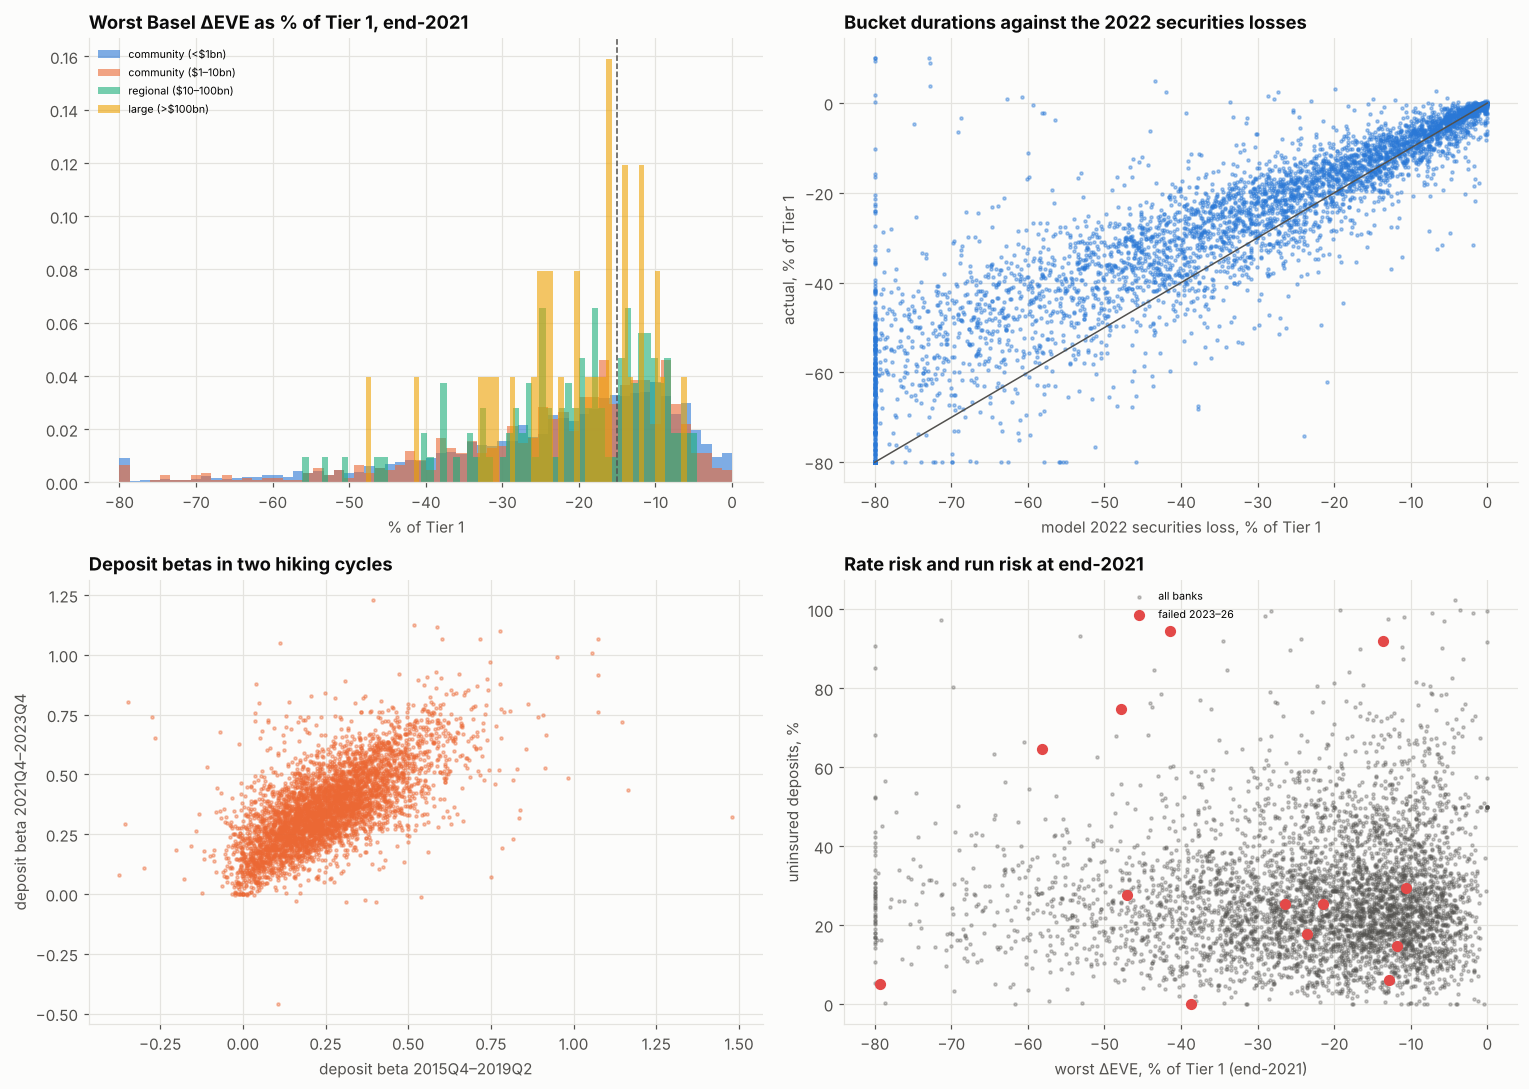

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for (g, d), col in zip(IRR.groupby("size", observed=True), PALETTE):
    a.hist(
        d["worst ΔEVE / T1"].clip(-0.8, 0.2) * 100,
        bins=60,
        alpha=0.6,
        color=col,
        label=g,
        density=True,
    )
a.axvline(-OUTLIER * 100, color=INK_2, ls="--", lw=1)
a.set_title("Worst Basel ΔEVE as % of Tier 1, end-2021")
a.set_xlabel("% of Tier 1")
a.legend(fontsize=7)
a = ax[0, 1]
lim = 0.8
a.scatter(
    (SECTEST["model"] / SECTEST["T1"]).clip(-lim, 0) * 100,
    (SECTEST["actual"] / SECTEST["T1"]).clip(-lim, 0.1) * 100,
    s=4,
    alpha=0.4,
    color=PALETTE[0],
)
a.plot([-lim * 100, 0], [-lim * 100, 0], color=INK_2, lw=1)
a.set_xlabel("model 2022 securities loss, % of Tier 1")
a.set_ylabel("actual, % of Tier 1")
a.set_title("Bucket durations against the 2022 securities losses")
a = ax[1, 0]
a.scatter(
    X2.loc[both, "previous-cycle beta"],
    BETA2[both],
    s=4,
    alpha=0.4,
    color=PALETTE[1],
)
a.set_xlabel("deposit beta 2015Q4–2019Q2")
a.set_ylabel("deposit beta 2021Q4–2023Q4")
a.set_title("Deposit betas in two hiking cycles")
a = ax[1, 1]
a.scatter(
    OUT["worst ΔEVE / T1"].clip(-0.8, 0.2) * 100,
    OUT["uninsured / deposits"] * 100,
    s=4,
    alpha=0.3,
    color=INK_2,
    label="all banks",
)
a.scatter(
    OUT.loc[OUT["failed 2023–26"], "worst ΔEVE / T1"].clip(-0.8, 0.2) * 100,
    OUT.loc[OUT["failed 2023–26"], "uninsured / deposits"] * 100,
    s=40,
    color=STATUS["red"],
    label="failed 2023–26",
)
a.set_xlabel("worst ΔEVE, % of Tier 1 (end-2021)")
a.set_ylabel("uninsured deposits, %")
a.set_title("Rate risk and run risk at end-2021")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_irrbb_call_reports")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Synthetic banks: ΔEVE by Basel scenario (% of Tier 1)",
        "Treasury curve: end-2021 and end-2022 (%)",
        "Share of banks above the 15% outlier threshold, by quarter",
        "Out-of-time scores (R² and rank correlation)",
    ),
)
for g, col in zip(SYNTH_BANKS.index, PALETTE):
    dash.add_trace(
        go.Bar(
            x=SCENARIOS,
            y=SYNTH_BANKS.loc[g, SCENARIOS] * 100,
            name=str(g),
            marker_color=col,
        ),
        1,
        1,
    )
tt = np.linspace(0.1, 30, 60)
for c, nm in [(c21, "end-2021"), (c22, "end-2022")]:
    dash.add_trace(go.Scatter(x=tt, y=c(tt) * 100, name=nm), 1, 2)
share = []
for q in sorted(CALL["date"].unique())[::2]:
    s = (
        CALL[CALL["date"] == q]
        .set_index("CERT")
        .sample(n=min(600, (CALL["date"] == q).sum()), random_state=SEED)
    )
    cq = zero_curve(q)
    w = [
        min(eve_change(bank_positions(b), cq, sc) for sc in SCENARIOS)
        / b["RBCT1J"]
        for _, b in s.iterrows()
    ]
    share.append((q, np.mean(np.array(w) < -OUTLIER)))
OUTLIER_TREND = pd.Series(
    dict(share), name="outlier share (sample of 600 banks)"
)
dash.add_trace(
    go.Scatter(
        x=OUTLIER_TREND.index, y=OUTLIER_TREND * 100, name="outliers %"
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=PRED.index, y=PRED.values, name="scores", marker_color=PALETTE[3]
    ),
    2,
    2,
)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title="IRRBB from U.S. call reports",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**At the end of 2021, most U.S. banks failed the Basel outlier test.** Measured from the call-report buckets with the standardised deposit caps, 62% of the 4,887 banks, holding 62% of the system's assets, would have lost more than 15% of Tier 1 capital under their worst Basel shock. The median bank lost 11% of Tier 1 under a parallel rise of 200 bp and 12% under the steepener. The worst case was:
- parallel up for 43% of banks;
- steepener for 25%;
- parallel down or short down for the rest, mostly banks funded by short deposits and lending at floating rates.

The share of outliers moved with the level of rates. It was about half in 2015–2019 and 60% at the end of 2021, when banks had just bought long assets at the lowest yields. It fell to about a third by 2026, as old fixed-rate assets matured and were replaced at higher rates.

**The size groups take their risk in different places.** The synthetic banks built from each group's summed buckets show:

| Synthetic bank | ΔEVE parallel up | ΔEVE short up | ΔEVE steepener | ΔNII +200 / NII | Uninsured deposits |
|---|---|---|---|---|---|
| Community (<\$1bn) | −14% | +4% | −15% | +0% | 28% |
| Community (\$1–10bn) | −11% | +6% | −15% | +2% | 37% |
| Regional (\$10–100bn) | −4% | +10% | −14% | +7% | 45% |
| Large (>\$100bn) | −5% | +11% | −17% | +18% | 52% |

Community banks hold long fixed-rate mortgages and securities against deposits that reprice slowly, so their value falls when rates rise and their income barely changes. Large banks lend more at floating rates and earn more when rates rise, but they fund themselves with the most uninsured deposits: their exposure is to the slope of the curve and to deposits leaving, not to the level of rates.

**The buckets got the 2022 securities losses roughly right.** Applying the actual 2022 move of the Treasury curve to each bank's securities buckets predicts a loss of \$776 billion; the call reports show \$611 billion (ratio 0.79). Across banks, the model loss as a share of Tier 1 has a correlation of 0.89 with the actual loss. By portfolio mix:
- **Mostly non-mortgage securities:** the model overstates the loss (actual/model 0.62).
- **Mostly mortgage-backed securities:** it understates it (1.16), because prepayments slowed when rates rose and stretched the duration of mortgage securities.

Part of the shortfall in actual losses is an accounting effect. Securities moved from available-for-sale to held-to-maturity in 2022 were transferred at fair value, so part of their loss sits in accumulated other comprehensive income and not in the gap between fair value and amortised cost.

**Deposit betas can be ranked a cycle ahead; their level cannot.** The median deposit beta rose from 0.24 in 2015–2019 (fed funds +2.2 points) to 0.35 in 2021–2023 (+5.3 points), and the spread across banks widened (10th–90th percentile 0.16–0.59). How well the second cycle's betas can be predicted from the first:

| Prediction of the 2021–2023 beta | Rank correlation | R² after rescaling to the new level |
|---|---|---|
| Ridge regression on the 2021 balance sheet and the previous beta | 0.72 | 0.26 |
| The bank's own 2015–2019 beta | 0.68 | — |
| LightGBM on the same features | 0.66 | 0.23 |
| One beta for all banks | — | 0.00 |

A bank's past behaviour is the strongest single predictor, and a linear model adds a little by using its deposit mix. Gradient boosting does not beat the linear model, because with one observation per bank and cycle there is little non-linearity to learn. None of the models predicts how much higher betas would be in a steeper cycle; that has to be an assumption, and the standard behavioural models that use a fixed beta understated it.

**The margin change is much harder.** Models trained on 2015–2019 rank the 2021–2023 change in net interest margin per point of fed funds with a rank correlation of about 0.5 (ridge 0.47, LightGBM 0.53), but explain almost none of its level (R² 0.04 and −0.08). The median margin gain per point of fed funds halved, from 0.07 to 0.04 points, as deposit costs caught up. The starting margin is the most important feature, followed by the share of non-interest-bearing deposits and of securities: banks that already had high margins or were funded by non-interest-bearing deposits gained least, because those deposits left or started to pay.

**The failed banks.** Thirteen banks failed between 2023 and 2026. They include Silicon Valley Bank, First Republic and Signature in 2023, and Republic First in 2024. At the end of 2021:
- **Silicon Valley Bank:** its worst ΔEVE (−41% of Tier 1) was worse than 88% of banks, and its uninsured share (95%) was higher than almost all of them.
- **First Republic:** −48% of Tier 1 and 75% uninsured.
- **Signature:** an ordinary −14% of Tier 1, but 92% uninsured: it failed on its depositors, not on its rate risk.

Across all banks, worst ΔEVE separates the failed banks from the rest with an AUC of 0.66, and the uninsured share alone with 0.52. The large failures needed both a large loss of economic value and depositors who could leave quickly. Small failures often come from fraud, credit losses or concentration, which this measure does not see. Thirteen events are too few to estimate a model; the table is descriptive.

**What this means for IRRBB.**
- **EVE and NII:** the standard measures, rebuilt only from public data, ranked banks' exposure correctly in 2021 and anticipated the securities losses of 2022.
- **Deposits:** what they understated was the behaviour of deposits. Betas rose with the size of the cycle, and uninsured deposits turned a value loss into a liquidity problem.
- **Model choice:** a linear model of betas using each bank's own history is as good as gradient boosting, and better than one beta for everyone. The useful next step is to model the run-off of uninsured deposits jointly with rate risk.

**Limitations.**
- **Buckets:** the call-report buckets report final maturity for fixed-rate positions and next repricing for floating ones. Amortisation and prepayment are approximated with level payments and a constant 8% prepayment speed. Derivative hedges, which many regional and large banks use, are not reported in a usable form and are ignored.
- **Positions covered:** non-rate-sensitive assets (equity securities, non-accrual loans, fixed assets) and other liabilities are left out, so ΔEVE is relative to Tier 1 rather than a full economic balance sheet.
- **Deposits:** they are split into transactional, non-transactional and wholesale from the deposit mix and the uninsured share. The standardised caps are applied at their maximum, which gives the longest deposit maturities the standard allows. Banks' own behavioural models may differ.
- **Curves:** the Treasury curve stands in for each bank's discount and reinvestment curve; credit spreads on loans are ignored.
- **ΔNII:** a constant balance sheet and an instantaneous shock, which is not what happened in 2022–2023, when balance sheets shrank and rates rose over 18 months.
- **Sample:** quarter-end data, banks that merged or failed drop out of later quarters, and the 2026 data are the latest available.

In [11]:
IRR.to_csv(OUT_DIR / "bank_level_eve_nii_2021.csv")
SYNTH_BANKS.to_csv(OUT_DIR / "synthetic_banks.csv")
SEC_BY_MIX.to_csv(OUT_DIR / "securities_loss_test.csv")
CYCLES.to_csv(OUT_DIR / "hiking_cycles.csv")
PRED.to_csv(OUT_DIR / "out_of_time_scores.csv")
FAILED_VIEW.to_csv(OUT_DIR / "failed_banks_measures.csv")
AUC.to_csv(OUT_DIR / "failure_auc.csv")
SHAP_NIM.to_csv(OUT_DIR / "nim_model_shap.csv")
OUTLIER_TREND.to_csv(OUT_DIR / "outlier_share_by_quarter.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_irrbb_call_reports.png, bank_level_eve_nii_2021.csv, dashboard.html, dashboard.png, failed_banks_measures.csv, failure_auc.csv, hiking_cycles.csv, nim_model_shap.csv, out_of_time_scores.csv, outlier_share_by_quarter.csv, securities_loss_test.csv, synthetic_banks.csv


## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2016). *Interest rate risk in the banking book* (Standards No. 368). Bank for International Settlements. https://www.bis.org/bcbs/publ/d368.htm
- Drechsler, I., Savov, A., & Schnabl, P. (2017). The deposits channel of monetary policy. *The Quarterly Journal of Economics, 132*(4), 1819–1876. https://doi.org/10.1093/qje/qjx019
- Drechsler, I., Savov, A., & Schnabl, P. (2021). Banking on deposits: Maturity transformation without interest rate risk. *The Journal of Finance, 76*(3), 1091–1143. https://doi.org/10.1111/jofi.13013
- English, W. B., Van den Heuvel, S. J., & Zakrajšek, E. (2018). Interest rate risk and bank equity valuations. *Journal of Monetary Economics, 98*, 80–97. https://doi.org/10.1016/j.jmoneco.2018.04.010
- Jiang, E. X., Matvos, G., Piskorski, T., & Seru, A. (2024). Monetary tightening and U.S. bank fragility in 2023: Mark-to-market losses and uninsured depositor runs? *Journal of Financial Economics, 159*, 103899. https://doi.org/10.1016/j.jfineco.2024.103899
- Federal Deposit Insurance Corporation. (2026). *BankFind Suite: Financial data* [Data set]. https://api.fdic.gov/banks/docs/

### Machine learning and deep learning

- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html